# Historical Flood Events — Data Collection

**Author:** Muhammad Kaleem — Climate Module Lead  
**Project:** Plexa — Multi-Modal Smart City Digital Twin and Cascading Resilience Engine

---

This notebook builds on `noaa_exploration.ipynb`, where I worked out how to 
pull NOAA rainfall and NYC 311 data using Hurricane Ida as a test case. 
Here I'm running the same pull across several historical NYC storms, so 
the model has more than one flood event to learn from — plus some lighter 
rain events for contrast.

### Events Being Pulled

| Event | Date | Severity |
|:---|:---|:---:|
| Hurricane Sandy | Oct 29, 2012 | Major |
| Hurricane Ida | Sep 1–2, 2021 | Major |
| September 2023 rainstorm | Sep 29, 2023 | Major |
| Southeast NY flooding | Jul 9–10, 2023 | Moderate |
| Tropical Storm Henri | Aug 21–22, 2021 | Moderate |
| Tropical Storm Isaias | Aug 4, 2020 | Light |
| Tropical Storm Fay | Jul 10, 2020 | Light |

### Data Sources

- **Rainfall:** NOAA GHCND · station `USW00094728` (Central Park)
- **Flood proxy:** NYC 311 · complaint type `Sewer` (no direct "flooding" category exists)

---

In [14]:
import os
import requests
import pandas as pd
from getpass import getpass

In [15]:
# Each event includes a couple of days before/after for context,
# not just the exact flood date
events = [
    {"name": "hurricane_sandy",   "start": "2012-10-27", "end": "2012-11-01"},
    {"name": "hurricane_ida",     "start": "2021-08-28", "end": "2021-09-02"},
    {"name": "storm_henri",       "start": "2021-08-20", "end": "2021-08-23"},
    {"name": "storm_isaias",      "start": "2020-08-03", "end": "2020-08-05"},
    {"name": "storm_fay",         "start": "2020-07-09", "end": "2020-07-11"},
    {"name": "sept_2023_storm",   "start": "2023-09-28", "end": "2023-09-30"},
    {"name": "se_ny_flooding",    "start": "2023-07-08", "end": "2023-07-11"},
]

STATION_ID = "GHCND:USW00094728"

In [16]:

token = getpass.getpass("Enter your NOAA CDO token: ")
headers = {"token": token}

os.makedirs("data/raw", exist_ok=True)

for event in events:
    params = {
        "datasetid": "GHCND",
        "stationid": STATION_ID,
        "datatypeid": "PRCP",
        "startdate": event["start"],
        "enddate": event["end"],
        "units": "metric",
        "limit": 1000
    }
    response = requests.get(
        "https://www.ncdc.noaa.gov/cdo-web/api/v2/data",
        headers=headers,
        params=params
    )
    records = response.json().get("results", [])
    if records:
        df = pd.DataFrame(records)
        df.to_csv(f"data/raw/rainfall_{event['name']}.csv", index=False)
        print(f"{event['name']}: {len(df)} rows saved")
    else:
        print(f"{event['name']}: no data returned")

Enter your NOAA CDO token:  ········


hurricane_sandy: 6 rows saved
hurricane_ida: 6 rows saved
storm_henri: 4 rows saved
storm_isaias: 3 rows saved
storm_fay: 3 rows saved
sept_2023_storm: 3 rows saved
se_ny_flooding: 4 rows saved


In [17]:
url = "https://data.cityofnewyork.us/resource/erm2-nwe9.json"

for event in events:
    all_records = []
    offset = 0
    while True:
        params = {
            "$where": f"created_date between '{event['start']}T00:00:00' and '{event['end']}T23:59:59' "
                       f"AND complaint_type = 'Sewer'",
            "$limit": 1000,
            "$offset": offset
        }
        response = requests.get(url, params=params)
        batch = response.json()
        if not batch:
            break
        all_records.extend(batch)
        offset += 1000

    if all_records:
        df_311 = pd.DataFrame(all_records)
        df_311.to_csv(f"data/raw/complaints_{event['name']}.csv", index=False)
        print(f"{event['name']}: {len(df_311)} complaints saved")
    else:
        print(f"{event['name']}: no complaints found")

hurricane_sandy: no complaints found
hurricane_ida: 5208 complaints saved
storm_henri: 1748 complaints saved
storm_isaias: 593 complaints saved
storm_fay: 895 complaints saved
sept_2023_storm: 2554 complaints saved
se_ny_flooding: 397 complaints saved


In [18]:
params_check = {
    "$where": "created_date between '2012-01-01T00:00:00' and '2012-12-31T23:59:59'",
    "$select": "count(*) as total"
}
response = requests.get(url, params=params_check)
print(response.json())

[{'total': '0'}]


### Note: Hurricane Sandy Excluded from Labeled Dataset

NYC's 311 API returns zero records for all of 2012, so Sandy — while 
still useful as a documented major flood event — cannot be paired with 
311 complaint data using the same method as the other events. Sandy's 
rainfall data is retained for reference, but it is excluded from the 
6-event labeled dataset used for model training.

## Combining Events into One Dataset

Aggregating rainfall + complaint counts by day across all 6 confirmed 
events, producing one combined table — this becomes the base dataset 
for EDA and later modeling.

In [22]:
labeled_events = [e for e in events if e["name"] != "hurricane_sandy"]

combined_rows = []

for event in labeled_events:
    rain_df = pd.read_csv(f"data/raw/rainfall_{event['name']}.csv")
    comp_df = pd.read_csv(f"data/raw/complaints_{event['name']}.csv")

    rain_df["date"] = pd.to_datetime(rain_df["date"]).dt.date
    comp_df["created_date"] = pd.to_datetime(comp_df["created_date"]).dt.date

    daily_complaints = comp_df.groupby("created_date").size().rename("sewer_complaints")

    merged = rain_df.groupby("date")["value"].sum().rename("rainfall_mm")
    merged = pd.DataFrame(merged).join(daily_complaints, how="left").reset_index()
    merged["sewer_complaints"] = merged["sewer_complaints"].fillna(0).astype(int)
    merged["event"] = event["name"]

    combined_rows.append(merged)

combined_df = pd.concat(combined_rows, ignore_index=True)
combined_df = combined_df.rename(columns={"date": "date"})
print(f"Combined dataset: {len(combined_df)} rows")
display(combined_df)

Combined dataset: 23 rows


,date,rainfall_mm,sewer_complaints,event
0,2021-08-28,0.0,71,hurricane_ida
1,2021-08-29,0.0,56,hurricane_ida
2,2021-08-30,0.0,112,hurricane_ida
3,2021-08-31,0.0,117,hurricane_ida
4,2021-09-01,181.1,1657,hurricane_ida
5,2021-09-02,2.5,3195,hurricane_ida
6,2021-08-20,0.0,89,storm_henri
7,2021-08-21,113.0,349,storm_henri
8,2021-08-22,67.8,881,storm_henri
9,2021-08-23,27.2,429,storm_henri


In [23]:
os.makedirs("data/processed", exist_ok=True)
combined_df.to_csv("data/processed/all_events_daily_summary.csv", index=False)
print("Saved combined dataset")

Saved combined dataset


## Visualizing Rainfall vs. Complaints Across All Events

A grid of charts, one per event, comparing daily rainfall against sewer 
complaints — showing whether the pattern seen in Ida (rain spike → 
complaint spike) holds consistently across other storms too.

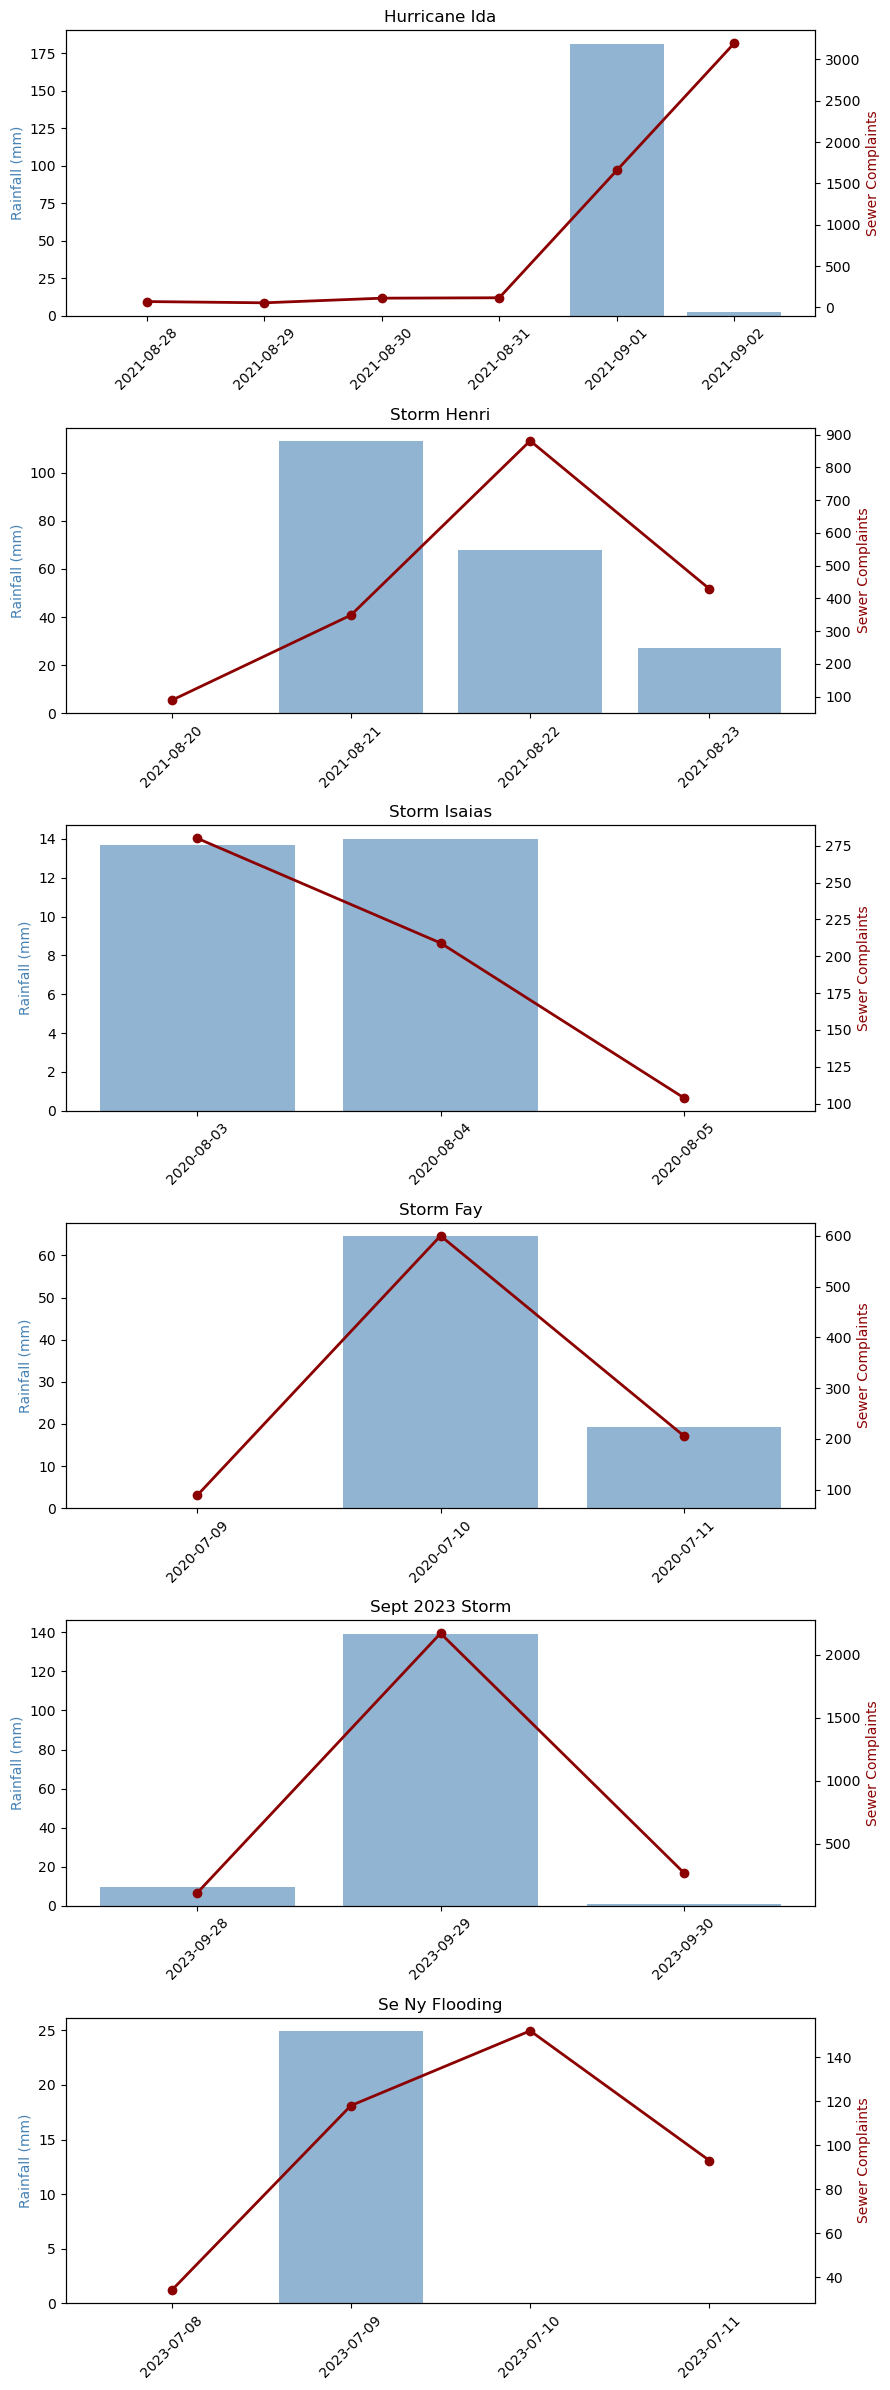

In [24]:
import matplotlib.pyplot as plt

event_names = combined_df["event"].unique()
n_events = len(event_names)

fig, axes = plt.subplots(n_events, 1, figsize=(9, 4 * n_events))

for ax, name in zip(axes, event_names):
    subset = combined_df[combined_df["event"] == name]

    ax2 = ax.twinx()
    ax.bar(subset["date"].astype(str), subset["rainfall_mm"], color="steelblue", alpha=0.6)
    ax2.plot(subset["date"].astype(str), subset["sewer_complaints"], color="darkred", marker="o", linewidth=2)

    ax.set_ylabel("Rainfall (mm)", color="steelblue")
    ax2.set_ylabel("Sewer Complaints", color="darkred")
    ax.set_title(name.replace("_", " ").title())
    ax.tick_params(axis="x", rotation=45)

fig.tight_layout()
plt.show()

## Observations Across Events

Most events show rainfall and complaint spikes aligning closely (Ida, 
Henri, Fay, Sept 2023 storm). Storm Isaias is a notable exception — 
rainfall stayed relatively flat while complaints declined, consistent 
with Isaias being primarily a wind/power-outage event rather than a 
major flooding event. This suggests rainfall alone won't perfectly 
predict flood impact for every storm type; wind speed or storm category 
may be a useful additional feature later.